# Orman-SSL: uçtan uca proje defteri

**Mehmet Oğuz Güneren · Danışman: Dr. Nida Kumbasar (TÜBİTAK BİLGEM) · 18 Ekim 2026**

Bu defter projenin **bütün kod yolunu** tek yerde, sırayla ve çalıştırılmış çıktılarıyla gösterir:

1. Veri: DISFOR kaynak tablolarından 24 ay × 10 bant model girdisine
2. Dürüst sınav: mekânsal bileşenler ve 5 coğrafi kat (spatial cross-validation)
3. Etiket bütçesi (label budget) alt kümeleri
4. Modeller: Random Forest, Temporal CNN, Transformer, masked-reconstruction SSL Transformer, step-matched kontrol
5. Canlı demo eğitimi (bir kat, bir seed) ve kayıtlı koşuyla karşılaştırma
6. Ana deney paper_v4: 180 koşunun tabloları, bootstrap aralıkları, şekiller
7. Uzantılar: paper_v5 (gruplama yarıçapı) ve paper_v6 (etiket eğrisi)
8. Keşif: Presto frozen probe
9. Ürün modeli advanced_v3: 10 üyeli ensemble ile gerçek çıkarım
10. Doğrulama (verify scripts, unit tests) ve tekrar üretim komutları

**Nasıl çalıştırılır:** Proje kökünde `.venv` kuruluysa `.venv/bin/python -m jupyter lab TESLIM_2026-10-18/Orman_SSL_Proje_Defteri.ipynb`. Bütün hücreler yukarıdan aşağı çalışır. Tam deneyi (180 + 75 + 225 koşu) yeniden eğitmek saatler sürer; bu defter kayıtlı koşuları okuyup **her tabloyu yeniden hesaplar**, eğitimi ise bir kat/seed için canlı gösterir. Tamamını yeniden koşmak için 10. bölümdeki komutlar kullanılır.

Projedeki asıl kod `src/orman_ssl/` ve `scripts/` altındadır; bu defter o kodu **içe aktarır ve kaynağını gösterir**, kopyalamaz. Böylece defterdeki kod ile deneyleri üreten kod birebir aynıdır.

In [1]:
# 0. Ortam ve yollar
import sys, json, math, time, inspect, platform, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'src/orman_ssl').exists(): ROOT = ROOT.parent     # defter TESLIM klasöründen açıldıysa
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / 'scripts'))
import torch, sklearn
import orman_ssl.advanced as adv
from orman_ssl.experiment import subset, normalize, rf_features
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 4)
print('Proje kökü :', ROOT)
print('Python', platform.python_version(), '| torch', torch.__version__, '| sklearn', sklearn.__version__, '| numpy', np.__version__)
def show_source(obj, title=None):
    display(Markdown(f'**Kaynak: `{title or obj.__name__}`**'))
    print(inspect.getsource(obj))

Proje kökü : /home/claude/proj
Python 3.13.16 | torch 2.14.1+cu130 | sklearn 1.9.1 | numpy 2.5.3


## 1. Veri: DISFOR'dan model girdisine

Kaynak: [JR-DIGITAL/DISFOR](https://huggingface.co/datasets/JR-DIGITAL/DISFOR), sabit revision `2562332e…`, EUPL-1.2. Ham tablolar `data/disfor/*.parquet`. Hazırlama kodu `scripts/prepare_disfor.py`; bu kod her konum için **iki tam takvim yılı** seçer, ay içindeki temiz gözlemlerin (kaynak `clear` bayrağı **ve** SCL 4/5) medyanını alır, boş ayları `observed=False` ile işaretler, her yılda ≥ 6 gözlenmiş ay ister ve 5 km + ortak olay bağlarıyla mekânsal bileşen kurar. Çıktı `data/processed/real_series.npz`.

In [2]:
d = dict(np.load(ROOT / 'data/processed/real_series.npz', allow_pickle=False))
meta = json.loads(str(d['metadata']))
print({k: (v.shape, str(v.dtype)) for k, v in d.items() if k != 'metadata'})
print('Sınıflar:', meta['classes'], '| Bantlar:', meta['channels'])
print('Konum sayısı:', len(d['y']), '| orman:', int((d['y']==0).sum()), '| kesim:', int((d['y']==1).sum()), '| mekânsal bileşen:', len(np.unique(d['groups'])))
prep = json.loads((ROOT / 'reports/disfor_preparation.json').read_text())
tab1 = pd.DataFrame([
    ['Downloaded sample table', 3822],
    ['− not high-confidence', -prep['rejected']['not_high_confidence']],
    ['− no unambiguous two-year window', -prep['rejected']['no_unambiguous_two_year_window']],
    ['− insufficient clear months', -prep['rejected']['insufficient_clear_months']],
    ['− wildfire excluded from binary task', -prep['rejected']['wildfire_excluded_from_primary_task']],
    ['Retained locations', prep['n']],
], columns=['Aşama (Table 1)', 'Konum'])
display(tab1)

{'x': ((2213, 24, 10), 'float32'), 'observed': ((2213, 24, 10), 'bool'), 'days': ((2213, 24), 'float32'), 'y': ((2213,), 'int64'), 'groups': ((2213,), 'int64'), 'ids': ((2213,), '<U16')}
Sınıflar: ['undisturbed_forest', 'clear_cut'] | Bantlar: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12']
Konum sayısı: 2213 | orman: 1937 | kesim: 276 | mekânsal bileşen: 874


,Aşama (Table 1),Konum
0,Downloaded sample table,3822
1,− not high-confidence,-598
2,− no unambiguous two-year window,-606
3,− insufficient clear months,-116
4,− wildfire excluded from binary task,-289
5,Retained locations,2213


In [3]:
# Örnek manifesti: her konumun kimliği, yılı, etiketi, koordinatı, kaynak kampanyası
manifest = pd.DataFrame(json.loads((ROOT / 'data/disfor/sample_manifest.json').read_text()))
display(manifest.head(8))
display(manifest.groupby(['dataset','label']).size().unstack(fill_value=0).rename(columns={0:'orman',1:'kesim'}).rename_axis('kampanya'))
print('Hedef yıl dağılımı:'); display(manifest.groupby(['year','label']).size().unstack(fill_value=0).rename(columns={0:'orman',1:'kesim'}))

,id,sample_id,year,label,lon,lat,dataset,source,source_description,confidence,source_cluster,cluster_description,group,split
0,disfor-0-2018,0,2018,0,-4.1221,36.7418,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,0.0,Damage polygons,1,train
1,disfor-2-2020,2,2020,0,-4.1192,36.7420,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,2.0,Damage polygons,1,train
2,disfor-3-2021,3,2021,0,-4.1285,36.7583,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,3.0,Damage polygons,1,train
3,disfor-4-2020,4,2020,1,-4.1282,36.7591,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,5.0,Damage polygons,1,train
4,disfor-5-2021,5,2021,1,-4.1292,36.7651,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,7.0,Damage polygons,1,train
5,disfor-6-2020,6,2020,1,-4.1312,36.7656,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,8.0,Damage polygons,1,train
6,disfor-7-2020,7,2020,1,-4.1298,36.7661,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,9.0,Damage polygons,1,train
7,disfor-10-2019,10,2019,1,-4.1349,36.7727,1,EFFIS,"Evoland Project, EFFIS Source of Wildfire Poly...",high,12.0,Damage polygons,1,train


label,orman,kesim
kampanya,,
1,211,79
2,1641,188
3,85,9


Hedef yıl dağılımı:


label,orman,kesim
year,,
2018,577,68
2019,312,76
2020,263,65
2021,246,40
2022,253,12
2023,286,15


In [4]:
# Hazırlama betiğinin tamamı (deneyi üreten kod; burada yalnız gösteriliyor, çalıştırılmıyor)
print((ROOT / 'scripts/prepare_disfor.py').read_text())

"""Versioned real-data adapter: retrospective 24-month forest condition classification."""
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
from shapely import from_wkb
from sklearn.neighbors import BallTree
root=Path(__file__).resolve().parents[1];sys.path.insert(0,str(root/'src'))
from orman_ssl.experiment import validate,split_groups
src=root/'data/disfor'
s=pd.read_parquet(src/'samples.parquet');l=pd.read_parquet(src/'labels.parquet');p=pd.read_parquet(src/'pixel_data.parquet')
p['date']=pd.to_datetime(p['timestamps'],utc=True)
for k in ['start','end']: l[k]=pd.to_datetime(l[k])
bands=['B02','B03','B04','B05','B06','B07','B08','B8A','B11','B12']
label_groups={int(k):v for k,v in l.groupby('sample_id')};pixel_groups={int(k):v for k,v in p.groupby('sample_id')}
rows=[];xs=[];masks=[];times=[]
rejected={}
def reject(k): rejected[k]=rejected.get(k,0)+1
for _,sample in s.iterrows():
 sid=int(sample.sample_id)
 if sample.confidence!='high':reject('n

### 1.1 Bir orman ve bir kesim serisi
NDVI = (B08 − B04)/(B08 + B04). Gri dikey bantlar gözlem olmayan (bulutlu) aylardır; model bunları doldurmaz, maskeden görür.

In [5]:
ids = list(d['ids'])
i_cut = ids.index('disfor-1733-2019') if 'disfor-1733-2019' in ids else int(np.where(d['y']==1)[0][0])
i_for = int(np.where(d['y']==0)[0][5])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, i, name in [(axes[0], i_for, 'Bozulmamış orman'), (axes[1], i_cut, 'Kesim (2. yılda)')]:
    x = d['x'][i]; m = d['observed'][i].any(-1)
    ndvi = (x[:,6]-x[:,2])/np.maximum(x[:,6]+x[:,2], 1)
    months = np.arange(1, 25)
    for t in np.where(~m)[0]: ax.axvspan(t+0.5, t+1.5, color='#cccccc', alpha=.5)
    ax.plot(months[m], ndvi[m], 'o-', color='#1a8fa6' if name.startswith('Boz') else '#c0583f')
    ax.axvline(12.5, color='k', lw=.8, ls='--'); ax.set_title(f'{name}: {ids[i]}'); ax.set_xlabel('ay'); ax.set_xticks([1,6,12,18,24])
axes[0].set_ylabel('NDVI'); plt.tight_layout(); plt.savefig(ROOT/'TESLIM_2026-10-18/figures/nb_ornek_seriler.png', dpi=150); plt.show()

## 2. Dürüst sınav: mekânsal bileşenler ve 5 coğrafi kat

Komşu pikseller neredeyse aynı seridir; rastgele bölme yapılırsa model komşusunu ezberler ve skor şişer (**spatial leakage**). Çözüm: 5 km içindeki konumlar ve aynı kaynak olayı paylaşan konumlar (kampanya 1 ve 3) bir çizgede birleştirilir; **connected component**'lar bölünmez; `StratifiedGroupKFold(5, shuffle=True, random_state=4192026)` ile beş kata dağıtılır. Aşağıdaki fonksiyon paper_v5'teki `component_groups`; 5 km için donmuş `d['groups']` ile birebir aynı sonucu verdiği doğrulanır.

In [6]:
from scientific_v5 import component_groups
show_source(component_groups)
raw_manifest = json.loads((ROOT / 'data/disfor/sample_manifest.json').read_text()); by_id = {r['id']: r for r in raw_manifest}
groups5 = component_groups([by_id[i] for i in ids], 5)   # konum sırası real_series.npz ile aynı olmalı
print('5 km bileşenleri donmuş gruplarla aynı mı?', bool(np.array_equal(groups5, d['groups'])), '| bileşen sayısı:', len(np.unique(groups5)))
sizes = np.unique(d['groups'], return_counts=True)[1]
print('Bileşen büyüklüğü: medyan', np.median(sizes), '| en büyük', sizes.max(), '| kesim içeren bileşen', len(np.unique(d['groups'][d['y']==1])))

**Kaynak: `component_groups`**

def component_groups(metadata, radius_km):
    """Match v4's transitive distance+event grouping, retaining sampling strata separately."""
    if radius_km <= 0:
        raise ValueError('Radius must be positive')
    n = len(metadata)
    if not n:
        raise ValueError('No locations')
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        a, b = find(i), find(j)
        if a != b:
            parent[b] = a

    coords = np.deg2rad([[r['lat'], r['lon']] for r in metadata])
    tree = BallTree(coords, metric='haversine')
    for i, neighbors in enumerate(tree.query_radius(coords, r=radius_km / EARTH_KM)):
        for j in neighbors:
            union(i, int(j))
    events = {}
    for i, row in enumerate(metadata):
        if row['source_cluster'] is not None and row['dataset'] in [1, 3]:
            key = (row['dataset'], row['source_cluster'])
    

In [7]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import BallTree
folds = json.loads((ROOT / 'experiments/paper_v4/folds.json').read_text())
coords = np.deg2rad(manifest.set_index('id').loc[ids, ['lat','lon']].values)
rows = []
for f in folds:
    tr, te = np.array(f['train_indices']), np.array(f['test_indices'])
    assert not (set(d['groups'][tr]) & set(d['groups'][te])), 'bileşen sızıntısı'
    nearest = BallTree(coords[tr], metric='haversine').query(coords[te], k=1)[0].min() * 6371.0088
    rows.append(dict(fold=f['fold']+1, train=len(tr), test=len(te), test_forest=int((d['y'][te]==0).sum()), test_cut=int((d['y'][te]==1).sum()),
                     test_components=len(np.unique(d['groups'][te])), nearest_train_km=round(float(nearest), 4)))
tab2 = pd.DataFrame(rows); display(tab2)
# Yeniden üret: aynı seed ile aynı katlar çıkıyor mu?
cv = StratifiedGroupKFold(5, shuffle=True, random_state=4192026)
same = all(list(te) == f['test_indices'] for (tr, te), f in zip(cv.split(d['x'], d['y'], d['groups']), folds))
print('Katlar aynı seed ile yeniden üretildi mi?', same)

,fold,train,test,test_forest,test_cut,test_components,nearest_train_km
0,1,1774,439,385,54,175,5.0021
1,2,1773,440,386,54,164,5.0110
2,3,1764,449,391,58,184,5.0011
3,4,1774,439,386,53,178,5.0011
4,5,1767,446,389,57,173,5.0021


Katlar aynı seed ile yeniden üretildi mi? True


## 3. Etiket bütçesi (label budget)

Her katın eğitim bölümünde yalnız bir kısım etiketli sayılır. `subset(y, train, fraction, seed)` sınıf içinde sabit rastgele sıra kullanır, `ceil(oran × sınıf sayısı)` örnek alır; bütçeler iç içedir (%5 ⊂ %10 ⊂ %20 ⊂ %50). Bütün yöntemler aynı etiketli kimlikleri görür. Etiketsiz kalan serilerin görüntüleri normalizasyonda herkes, ön eğitimde yalnız SSL tarafından kullanılır.

In [8]:
show_source(subset)
tr0 = np.array(folds[0]['train_indices'])
tab = []
for b in [.05, .1, .2, .5, 1.]:
    lab = subset(d['y'], tr0, b, 7)
    tab.append(dict(budget=f'{int(b*100)}%', n_labeled=len(lab), labeled_forest=int((d['y'][lab]==0).sum()), labeled_cut=int((d['y'][lab]==1).sum()),
                    step_matched_epochs=math.ceil((60*math.ceil(len(tr0)/64)+40*math.ceil(len(lab)/64))/math.ceil(len(lab)/64))))
display(pd.DataFrame(tab))
s5, s20 = set(subset(d['y'], tr0, .05, 7)), set(subset(d['y'], tr0, .2, 7)); print('%5 ⊂ %20 (seed 7, kat 1):', s5 <= s20)

**Kaynak: `subset`**

def subset(y, train, fraction, seed):
    rng = np.random.default_rng(seed)
    # Per-class nested ordering: label budgets are comparable within each seed.
    return np.concatenate([rng.permutation(train[y[train] == k])[:max(1, int(np.ceil((y[train] == k).sum() * fraction)))] for k in np.unique(y)])



,budget,n_labeled,labeled_forest,labeled_cut,step_matched_epochs
0,5%,90,78,12,880
1,10%,179,156,23,600
2,20%,356,311,45,320
3,50%,887,776,111,160
4,100%,1774,1552,222,100


%5 ⊂ %20 (seed 7, kat 1): True


## 4. Modeller

Dört yarışmacı ve kontroller (`src/orman_ssl/advanced.py`):

* **rf_leaf4** – Random Forest, 500 ağaç, `min_samples_leaf=4`, `max_features=0.7`, `balanced_subsample`; girdi 60 özet özellik (`rf_features`).
* **cnn64** – Temporal CNN: width 64, 3 residual block, dilation 1/2/4, GroupNorm, GELU, dropout 0.2.
* **transformer48** – 2 encoder layer, 4 head, width 48, feed-forward 144, dropout 0.15; gözlenmemiş aylar key-padding ile maskelenir; observed-time mean pooling.
* **ssl_transformer48** – aynı Transformer; önce 60 epoch **masked reconstruction pretraining** (`block_mask`: 2–6 aylık blok + 2 bant gizlenir, Smooth L1 yalnız gizlenmiş-ama-gözlenmiş hücrelerde), sonra sınıflandırıcı başı başlangıç ağırlığına sıfırlanıp 40 epoch ince ayar.
* **step_matched** – transformer48, SSL'in toplam optimizer adımı kadar epoch (20% bütçede 320).

Ortak tarif: AdamW (wd 0.01), batch 64, class-weighted cross-entropy, label smoothing 0.02, grad-clip 1, ayları %10 silme (`augment`). Early stopping, validation seçimi, kalibrasyon, eşik ayarı **yok**; eşik 0.5.

In [9]:
show_source(adv.ResidualBlock); show_source(adv.TemporalNet); show_source(adv.block_mask); show_source(adv.augment)

**Kaynak: `ResidualBlock`**

class ResidualBlock(nn.Module):
    def __init__(self,width,dilation,dropout):
        super().__init__()
        self.net=nn.Sequential(nn.Conv1d(width,width,3,padding=dilation,dilation=dilation),
            nn.GroupNorm(4,width),nn.GELU(),nn.Dropout(dropout),
            nn.Conv1d(width,width,3,padding=dilation,dilation=dilation),nn.GroupNorm(4,width),nn.GELU())
    def forward(self,x): return x+self.net(x)



**Kaynak: `TemporalNet`**

class TemporalNet(nn.Module):
    def __init__(self,config,channels=10):
        super().__init__();self.kind=config['kind'];width=config['width']
        self.embed=nn.Linear(channels*2+3,width)
        if self.kind=='cnn':
            self.encoder=nn.Sequential(*[ResidualBlock(width,v,config['dropout']) for v in [1,2,4]])
        else:
            layer=nn.TransformerEncoderLayer(width,4,width*3,dropout=config['dropout'],activation='gelu',batch_first=True,norm_first=False)
            self.encoder=nn.TransformerEncoder(layer,2,enable_nested_tensor=False)
        self.classifier=nn.Sequential(nn.LayerNorm(width),nn.Dropout(config['dropout']),nn.Linear(width,2))
        self.reconstruct=nn.Linear(width,channels)
    def forward(self,x,mask,days):
        observed=mask.any(-1)
        time_features=torch.stack([days/730,torch.sin(days*2*math.pi/365.25),torch.cos(days*2*math.pi/365.25)],-1)
        # masked_fill avoids NaN * 0 contaminating the network.
        h=self.embed(torch.cat([x.

**Kaynak: `block_mask`**

def block_mask(mask):
    n,t,c=mask.shape
    hidden=torch.zeros_like(mask)
    for i in range(n):
        length=int(torch.randint(2,7,()).item());start=int(torch.randint(0,t-length+1,()).item())
        hidden[i,start:start+length]=True
        bands=torch.randperm(c)[:2];hidden[i,:,bands]=True
    hidden &= mask
    for i in range(n):
        observed=torch.nonzero(mask[i],as_tuple=False)
        if len(observed)>1 and (mask[i]&~hidden[i]).sum()==0:
            j,k=observed[0];hidden[i,j,k]=False
        if not hidden[i].any() and len(observed)>1:
            j,k=observed[-1];hidden[i,j,k]=True
    return hidden



**Kaynak: `augment`**

def augment(mask):
    result=mask & ~(torch.rand(mask.shape[:2])<.1).unsqueeze(-1)
    empty=~result.any((1,2))
    result[empty]=mask[empty]
    return result



In [10]:
show_source(adv.fit); show_source(rf_features); show_source(normalize)

**Kaynak: `fit`**

def fit(config,d,train,val=None,seed=7,epochs=80,pre_epochs=60,labeled=None,early_stop=True):
    torch.set_num_threads(2);torch.manual_seed(seed);np.random.seed(seed)
    z,mean,std=normalize(d['x'],d['observed'],train)
    labeled=train if labeled is None else labeled
    y=d['y'];counts=np.bincount(y[labeled],minlength=2)
    if not counts.all():raise ValueError('Training labels need both classes')
    if config['kind']=='rf':
        model=RandomForestClassifier(n_estimators=500,min_samples_leaf=config['leaf'],max_features=.7,
                                     class_weight='balanced_subsample',n_jobs=2,random_state=seed)
        features=rf_features(z,d['observed']);model.fit(features[labeled],y[labeled])
        score=None if val is None else float(f1_score(y[val],model.predict(features[val]),average='macro'))
        return dict(model=model,mean=mean.tolist(),std=std.tolist(),config=config,seed=seed,epochs=0),dict(best_epoch=0,validation_macro_f1=score,history=[])
    x=torch.

**Kaynak: `rf_features`**

def rf_features(x, m):
    # No imputation fit on held-out data; normalized missing entries remain zero.
    count = m.sum(1).clip(1)
    mean = (x * m).sum(1) / count
    std = np.sqrt(((x - mean[:, None]) ** 2 * m).sum(1) / count)
    low = np.where(m, x, np.inf).min(1)
    high = np.where(m, x, -np.inf).max(1)
    low[~np.isfinite(low)] = 0; high[~np.isfinite(high)] = 0
    # Time-order information through first-half / second-half means.
    h = x.shape[1] // 2
    delta = (x[:, h:] * m[:, h:]).sum(1) / m[:, h:].sum(1).clip(1) - (x[:, :h] * m[:, :h]).sum(1) / m[:, :h].sum(1).clip(1)
    return np.concatenate([mean, std, low, high, delta, m.mean(1)], axis=1)



**Kaynak: `normalize`**

def normalize(x, observed, train):
    z = np.where(observed[train], x[train], np.nan)
    if not np.isfinite(z).any(axis=(0, 1)).all():
        raise ValueError('Every channel needs observed training values')
    mean = np.nanmean(z, axis=(0, 1))
    std = np.maximum(np.nanstd(z, axis=(0, 1)), 1e-5)
    return np.where(observed, (x - mean) / std, 0).astype('float32'), mean, std



In [11]:
cfg = {c['name']: c for c in adv.CONFIGS}
for name in ['cnn64', 'transformer48']:
    net = adv.TemporalNet(cfg[name]); print(f'{name}: {sum(p.numel() for p in net.parameters()):,} parametre')

cnn64: 77,324 parametre
transformer48: 49,068 parametre


## 5. Canlı demo eğitimi: kat 1, seed 7, %20 etiket

Aşağıda dört yöntem (+ step-matched) gerçekten eğitilir ve kat 1'in test noktalarında ölçülür; ardından `experiments/paper_v4/runs/` içindeki kayıtlı koşuyla karşılaştırılır. Kayıtlı koşular macOS'ta üretildi. Başka işletim sistemi / torch sürümünde kısa eğitimler (RF, CNN, 40 epoch Transformer) neredeyse birebir çıkar; uzun eğitimlerde (60 epoch ön eğitim, 320 epoch step-matched) float32 yuvarlama farkları yüzlerce adımda birikir ve tek noktalardaki olasılıklar belirgin sapabilir. Bu yüzden karşılaştırmayı tek kat/tek seed değil, 5 kat × 3 seed ortalamasıyla yapıyoruz; o ortalamalar 6. bölümde kayıtlarla 1e-9 hassasiyetle örtüşür. Süre: CPU'da ~2–3 dakika.

In [12]:
from sklearn.metrics import f1_score, average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix
def scores(y, p):
    q = p >= .5; cm = confusion_matrix(y, q, labels=[0,1])
    return dict(macro_f1=f1_score(y, q, average='macro'), AP=average_precision_score(y, p), roc_auc=roc_auc_score(y, p),
                brier=brier_score_loss(y, p), cut_recall=cm[1,1]/cm[1].sum(), tn=cm[0,0], fp=cm[0,1], fn=cm[1,0], tp=cm[1,1])
fold, seed, budget = 0, 7, .2
tr, te = np.array(folds[fold]['train_indices']), np.array(folds[fold]['test_indices'])
lab = subset(d['y'], tr, budget, seed)
steps = math.ceil((60*math.ceil(len(tr)/64)+40*math.ceil(len(lab)/64))/math.ceil(len(lab)/64))
plan = [('rf_leaf4','rf_leaf4',40), ('cnn64','cnn64',40), ('transformer48','transformer48',40), ('ssl_transformer48','ssl_transformer48',40), ('step_matched','transformer48',steps)]
demo = {}
for name, config_name, epochs in plan:
    t0 = time.time()
    state, log = adv.fit(cfg[config_name], d, tr, seed=seed, epochs=epochs, pre_epochs=60, labeled=lab, early_stop=False)
    p = adv.state_probability(state, adv.view(d, te))
    stored = json.loads((ROOT / f'experiments/paper_v4/runs/{name}_f{fold}_s{seed}_b{budget}.json').read_text())
    demo[name] = dict(**scores(d['y'][te], p), seconds=round(time.time()-t0,1), stored_macro_f1=stored['metrics']['macro_f1'],
                      max_prob_diff=float(np.max(np.abs(p - np.array(stored['probabilities'])))))
    print(f'{name:20s} macro-F1 {demo[name]["macro_f1"]:.4f}  (kayıtlı {stored["metrics"]["macro_f1"]:.4f})  {demo[name]["seconds"]} s')
display(pd.DataFrame(demo).T)

rf_leaf4             macro-F1 0.8994  (kayıtlı 0.9035)  1.6 s


cnn64                macro-F1 0.9385  (kayıtlı 0.9385)  5.0 s


transformer48        macro-F1 0.9035  (kayıtlı 0.9035)  5.9 s


ssl_transformer48    macro-F1 0.9214  (kayıtlı 0.9169)  52.7 s


step_matched         macro-F1 0.9285  (kayıtlı 0.9297)  44.3 s


,macro_f1,AP,roc_auc,brier,cut_recall,tn,fp,fn,tp,seconds,stored_macro_f1,max_prob_diff
rf_leaf4,0.8994,0.9268,0.9812,0.0409,0.9259,368.0,17.0,4.0,50.0,1.6,0.9035,6.6487e-03
cnn64,0.9385,0.9316,0.9659,0.0227,0.8333,383.0,2.0,9.0,45.0,5.0,0.9385,4.0430e-04
transformer48,0.9035,0.9295,0.9714,0.0413,0.8704,373.0,12.0,7.0,47.0,5.9,0.9035,8.9407e-07
ssl_transformer48,0.9214,0.9331,0.9725,0.0330,0.8704,377.0,8.0,7.0,47.0,52.7,0.9169,1.0930e-01
step_matched,0.9285,0.9022,0.9414,0.0296,0.8333,381.0,4.0,9.0,45.0,44.3,0.9297,5.9750e-01


In [13]:
# SSL ön eğitim kaybı ve ince ayar kaybı (kayıtlı koşudan)
r = json.loads((ROOT / 'experiments/paper_v4/runs/ssl_transformer48_f0_s7_b0.2.json').read_text())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(r['log']['pretrain_loss']); axes[0].set_title('SSL pretraining: Smooth L1 (60 epoch)'); axes[0].set_xlabel('epoch')
axes[1].plot([h['loss'] for h in r['log']['history']]); axes[1].set_title('Fine-tuning: weighted cross-entropy (40 epoch)'); axes[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 6. Ana deney paper_v4: 180 koşu

Protokol deneyden önce donduruldu (`protocol.json`, `signature.json`). Aşağıda bütün koşu kayıtları okunur, her yöntem/bütçe/seed için beş katın test tahminleri 2.213 noktada **birleştirilir (pooled out-of-fold)**, metrikler yeniden hesaplanır ve `analysis.json` ile karşılaştırılır.

In [14]:
runs = [json.loads(p.read_text()) for p in sorted((ROOT / 'experiments/paper_v4/runs').glob('*.json'))]
print('Koşu sayısı:', len(runs))
runs_df = pd.DataFrame([dict(method=r['method'], budget=r['budget'], seed=r['seed'], fold=r['fold'], n_labeled=r['n_labeled'], epochs=r['epochs'],
                             fold_macro_f1=r['metrics']['macro_f1'], seconds=r['seconds']) for r in runs])
display(runs_df.groupby(['method','budget']).agg(fits=('fold','size'), n_labeled=('n_labeled','min'), epochs=('epochs','max'), mean_fold_f1=('fold_macro_f1','mean'), total_sec=('seconds','sum')))
lookup = {v: i for i, v in enumerate(ids)}; n = len(ids); y = d['y']
pooled = {}
for (method, budget), grp in runs_df.groupby(['method','budget']):
    P = []
    for seed in [7,17,27]:
        p = np.full(n, np.nan)
        for r in runs:
            if r['method']==method and r['budget']==budget and r['seed']==seed:
                p[[lookup[i] for i in r['test_ids']]] = r['probabilities']
        assert np.isfinite(p).all(); P.append(p)
    pooled[(method, budget)] = np.stack(P)
NAMES = {'rf_leaf4':'Random forest','cnn64':'Temporal CNN','transformer48':'Transformer (40 ep.)','ssl_transformer48':'Block+band SSL','iid_ssl':'Independent-cell SSL','step_matched':'Step-matched Transformer','mask_only':'Observation mask only','metadata_only':'Location/year/campaign'}
def summary_table(keys):
    out = []
    for k in keys:
        s = [scores(y, p) for p in pooled[k]]
        out.append(dict(labels=f'{int(k[1]*100)}%', method=NAMES[k[0]], macro_f1=np.mean([v['macro_f1'] for v in s]), sd=np.std([v['macro_f1'] for v in s], ddof=1),
                        AP=np.mean([v['AP'] for v in s]), roc_auc=np.mean([v['roc_auc'] for v in s]), cut_recall=np.mean([v['cut_recall'] for v in s]), brier=np.mean([v['brier'] for v in s])))
    return pd.DataFrame(out)
display(Markdown('**Table 3 — Primary pooled out-of-fold results (mean over 3 seeds; SD = seed standard deviation)**'))
tab3 = summary_table([(m,b) for b in [.2,1.] for m in ['rf_leaf4','cnn64','transformer48','ssl_transformer48']]); display(tab3)
display(Markdown('**Table 4 — Controls at 20% labels**'))
tab4 = summary_table([(m,.2) for m in ['transformer48','ssl_transformer48','iid_ssl','step_matched','mask_only','metadata_only']]); display(tab4)

Koşu sayısı: 180


fits  n_labeled  epochs  mean_fold_f1  total_sec
method            budget                                                  
cnn64             0.2       15        354      40        0.8741   107.5924
                  1.0       15       1764      40        0.9310   509.6806
iid_ssl           0.2       15        354      40        0.8620   311.5242
mask_only         0.2       15        354       0        0.5498     5.4247
metadata_only     0.2       15        354       0        0.6436     4.7737
rf_leaf4          0.2       15        354      40        0.8449     8.5958
                  1.0       15       1764      40        0.8668    56.4260
ssl_transformer48 0.2       15        354      40        0.8692   357.1013
                  1.0       15       1764      40        0.9293   508.7159
step_matched      0.2       15        354     320        0.8988   283.9696
transformer48     0.2       15        354      40        0.8343    39.5106
                  1.0       15       1764      40        0.9283   191.6802

**Table 3 — Primary pooled out-of-fold results (mean over 3 seeds; SD = seed standard deviation)**

,labels,method,macro_f1,sd,AP,roc_auc,cut_recall,brier
0,20%,Random forest,0.8452,0.0058,0.7969,0.9128,0.7295,0.0561
1,20%,Temporal CNN,0.8721,0.0081,0.8494,0.9314,0.7983,0.0495
2,20%,Transformer (40 ep.),0.8322,0.0236,0.8419,0.9206,0.7995,0.0670
3,20%,Block+band SSL,0.8690,0.0043,0.8636,0.9419,0.8007,0.0492
4,100%,Random forest,0.8669,0.0028,0.8382,0.9374,0.7101,0.0447
5,100%,Temporal CNN,0.9299,0.0071,0.9273,0.9679,0.8853,0.0300
6,100%,Transformer (40 ep.),0.9285,0.0057,0.9227,0.9591,0.8720,0.0297
7,100%,Block+band SSL,0.9287,0.0049,0.9337,0.9700,0.8756,0.0286


**Table 4 — Controls at 20% labels**

,labels,method,macro_f1,sd,AP,roc_auc,cut_recall,brier
0,20%,Transformer (40 ep.),0.8322,0.0236,0.8419,0.9206,0.7995,0.0670
1,20%,Block+band SSL,0.8690,0.0043,0.8636,0.9419,0.8007,0.0492
2,20%,Independent-cell SSL,0.8609,0.0098,0.8604,0.9378,0.8068,0.0540
3,20%,Step-matched Transformer,0.8987,0.0112,0.8445,0.9116,0.7971,0.0417
4,20%,Observation mask only,0.5515,0.0129,0.1738,0.5774,0.2826,0.1736
5,20%,Location/year/campaign,0.6455,0.0300,0.3979,0.7943,0.3949,0.1115


In [15]:
# analysis.json ile çapraz kontrol (1e-9 toleransla aynı olmalı)
A = json.loads((ROOT / 'experiments/paper_v4/analysis.json').read_text())
ref = {(r['method'], r['budget']): r['macro_f1_mean'] for r in A['summary']}
mx = max(abs(ref[k] - np.mean([scores(y,p)['macro_f1'] for p in pooled[k]])) for k in ref)
print('Yeniden hesap ile analysis.json arasındaki en büyük fark:', f'{mx:.2e}')

Yeniden hesap ile analysis.json arasındaki en büyük fark: 0.00e+00


### 6.1 Paired spatial-component bootstrap
874 bileşen yerine koyarak 2.000 kez örneklenir; her çekimde aynı ağırlıklar iki yönteme de uygulanır, üç seed'in farkı ortalanır; %2.5–%97.5 yüzdelikleri aralıktır. Nokta değil **bileşen** örneklenir çünkü komşu noktalar bağımsız değildir.

In [16]:
def macro(y, p, w):
    q = p >= .5
    tp = np.sum(w*(q&(y==1))); tn = np.sum(w*((~q)&(y==0))); fp = np.sum(w*(q&(y==0))); fn = np.sum(w*((~q)&(y==1)))
    return .5*((2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0)+(2*tn/(2*tn+fp+fn) if 2*tn+fp+fn else 0))
uniq, gi = np.unique(d['groups'], return_inverse=True); rng = np.random.default_rng(120926)
comparators = ['transformer48','step_matched','iid_ssl','rf_leaf4','cnn64']; draws = {c: [] for c in comparators}
for _ in range(2000):
    w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[gi]
    if not w[y==0].sum() or not w[y==1].sum(): continue
    ssl = np.mean([macro(y, p, w) for p in pooled[('ssl_transformer48', .2)]])
    for c in comparators: draws[c].append(ssl - np.mean([macro(y, p, w) for p in pooled[(c, .2)]]))
boot = pd.DataFrame([dict(comparison=f'SSL − {NAMES[c]}', mean_diff=np.mean([macro(y,a,np.ones(n))-macro(y,b,np.ones(n)) for a,b in zip(pooled[('ssl_transformer48',.2)], pooled[(c,.2)])]),
                          ci_low=np.quantile(draws[c], .025), ci_high=np.quantile(draws[c], .975), role='primary' if c=='transformer48' else 'exploratory') for c in comparators])
display(boot)
print('analysis.json kayıtlı aralıklar:'); display(pd.DataFrame(A['paired_comparisons'])[['comparator','mean_difference','paired_group_bootstrap_95_interval']])

,comparison,mean_diff,ci_low,ci_high,role
0,SSL − Transformer (40 ep.),0.0368,0.0245,0.0506,primary
1,SSL − Step-matched Transformer,-0.0297,-0.0430,-0.0179,exploratory
2,SSL − Independent-cell SSL,0.0080,-0.0013,0.0178,exploratory
3,SSL − Random forest,0.0238,0.0016,0.0450,exploratory
4,SSL − Temporal CNN,-0.0031,-0.0194,0.0125,exploratory


analysis.json kayıtlı aralıklar:


,comparator,mean_difference,paired_group_bootstrap_95_interval
0,transformer48,0.0368,"[0.02446258159615691, 0.050571506831696096]"
1,step_matched,-0.0297,"[-0.04303972495281699, -0.01793258940328925]"
2,iid_ssl,0.0080,"[-0.001324553985598195, 0.017789216882333602]"
3,rf_leaf4,0.0238,"[0.001609985739241088, 0.04503707335268573]"
4,cnn64,-0.0031,"[-0.019420362121912792, 0.012538001029899614]"


**Figure 2 — Primary comparisons at 20% and 100% labels**

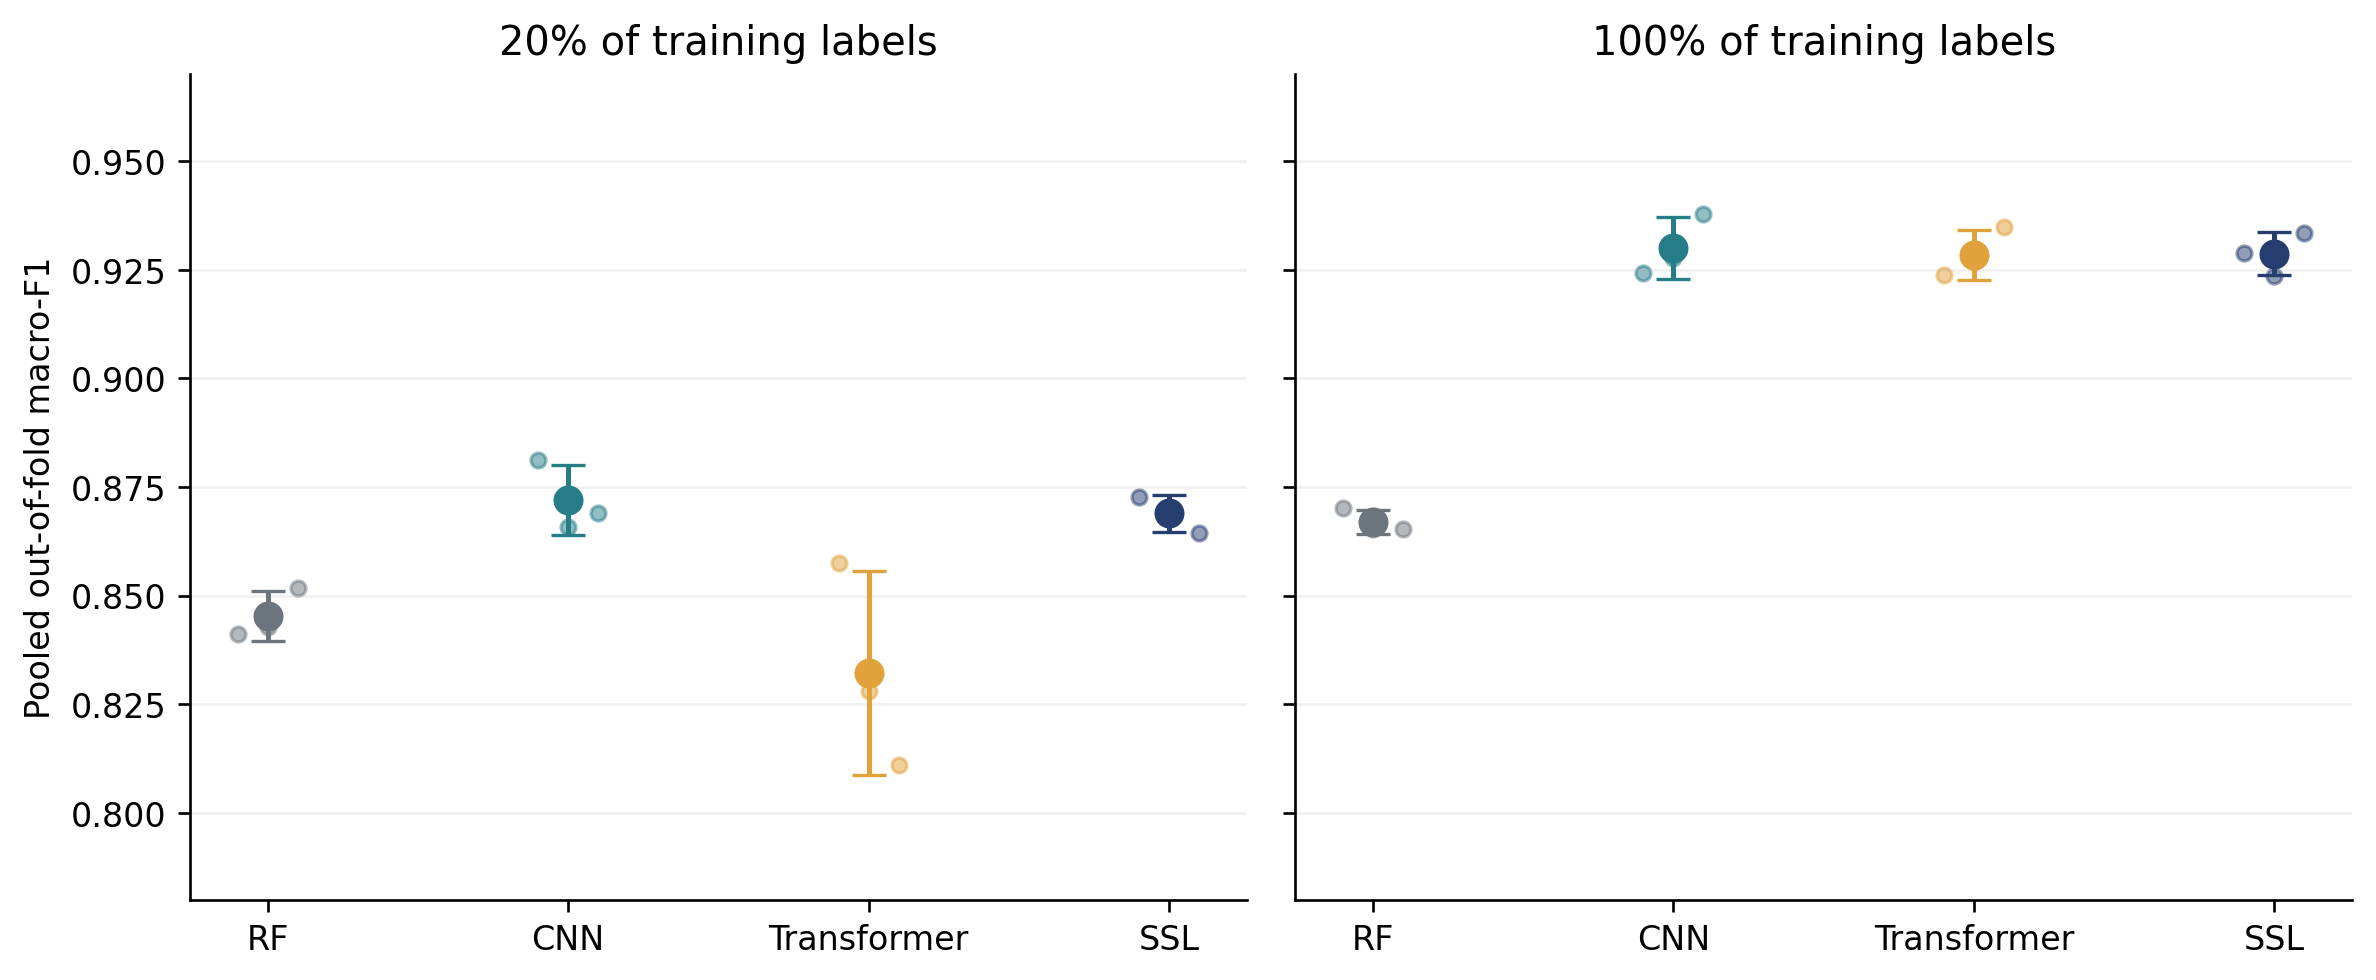

**Figure 3 — Controls and paired bootstrap intervals**

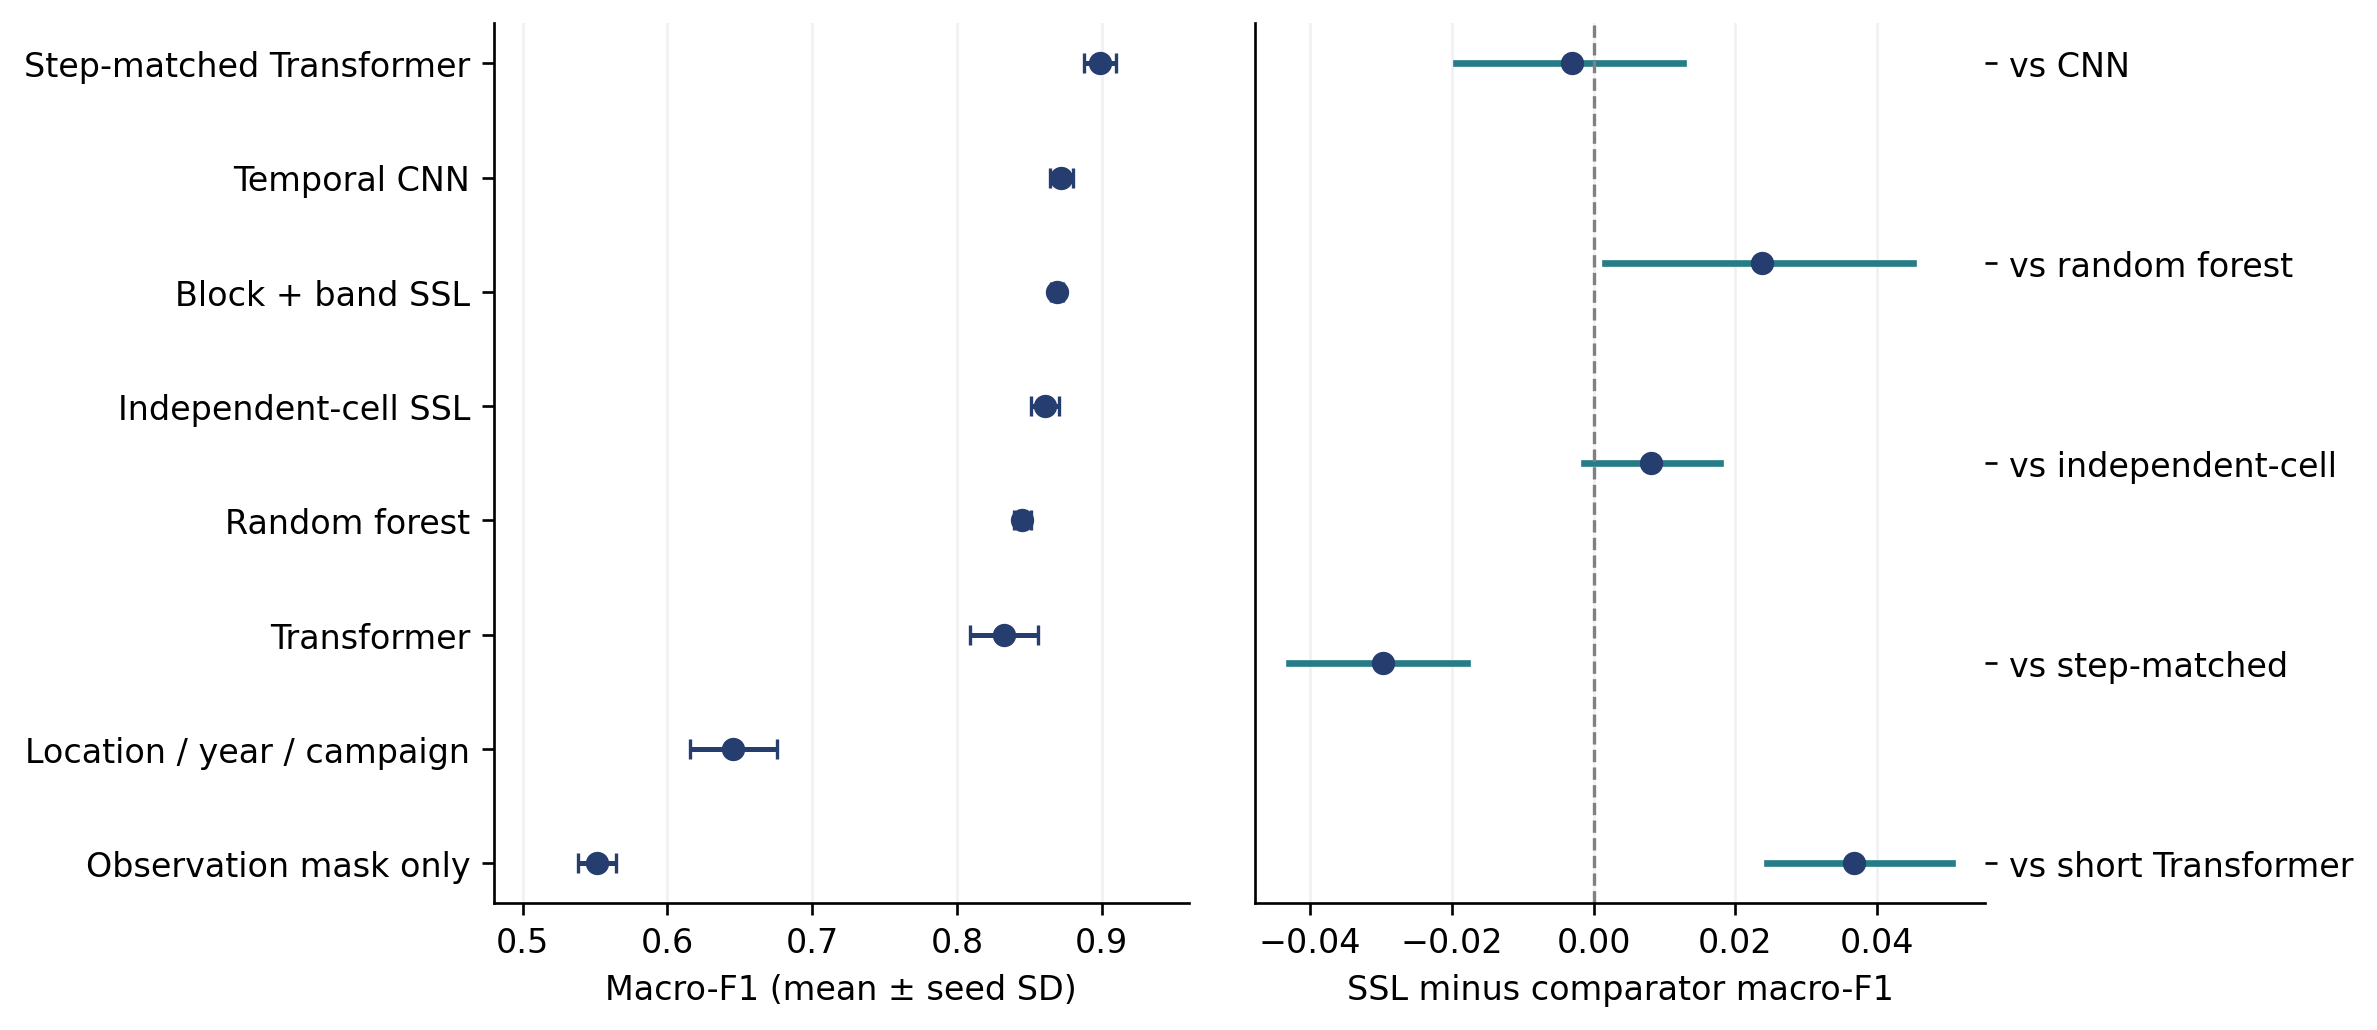

**Figure 1 — Locations and observed-month support**

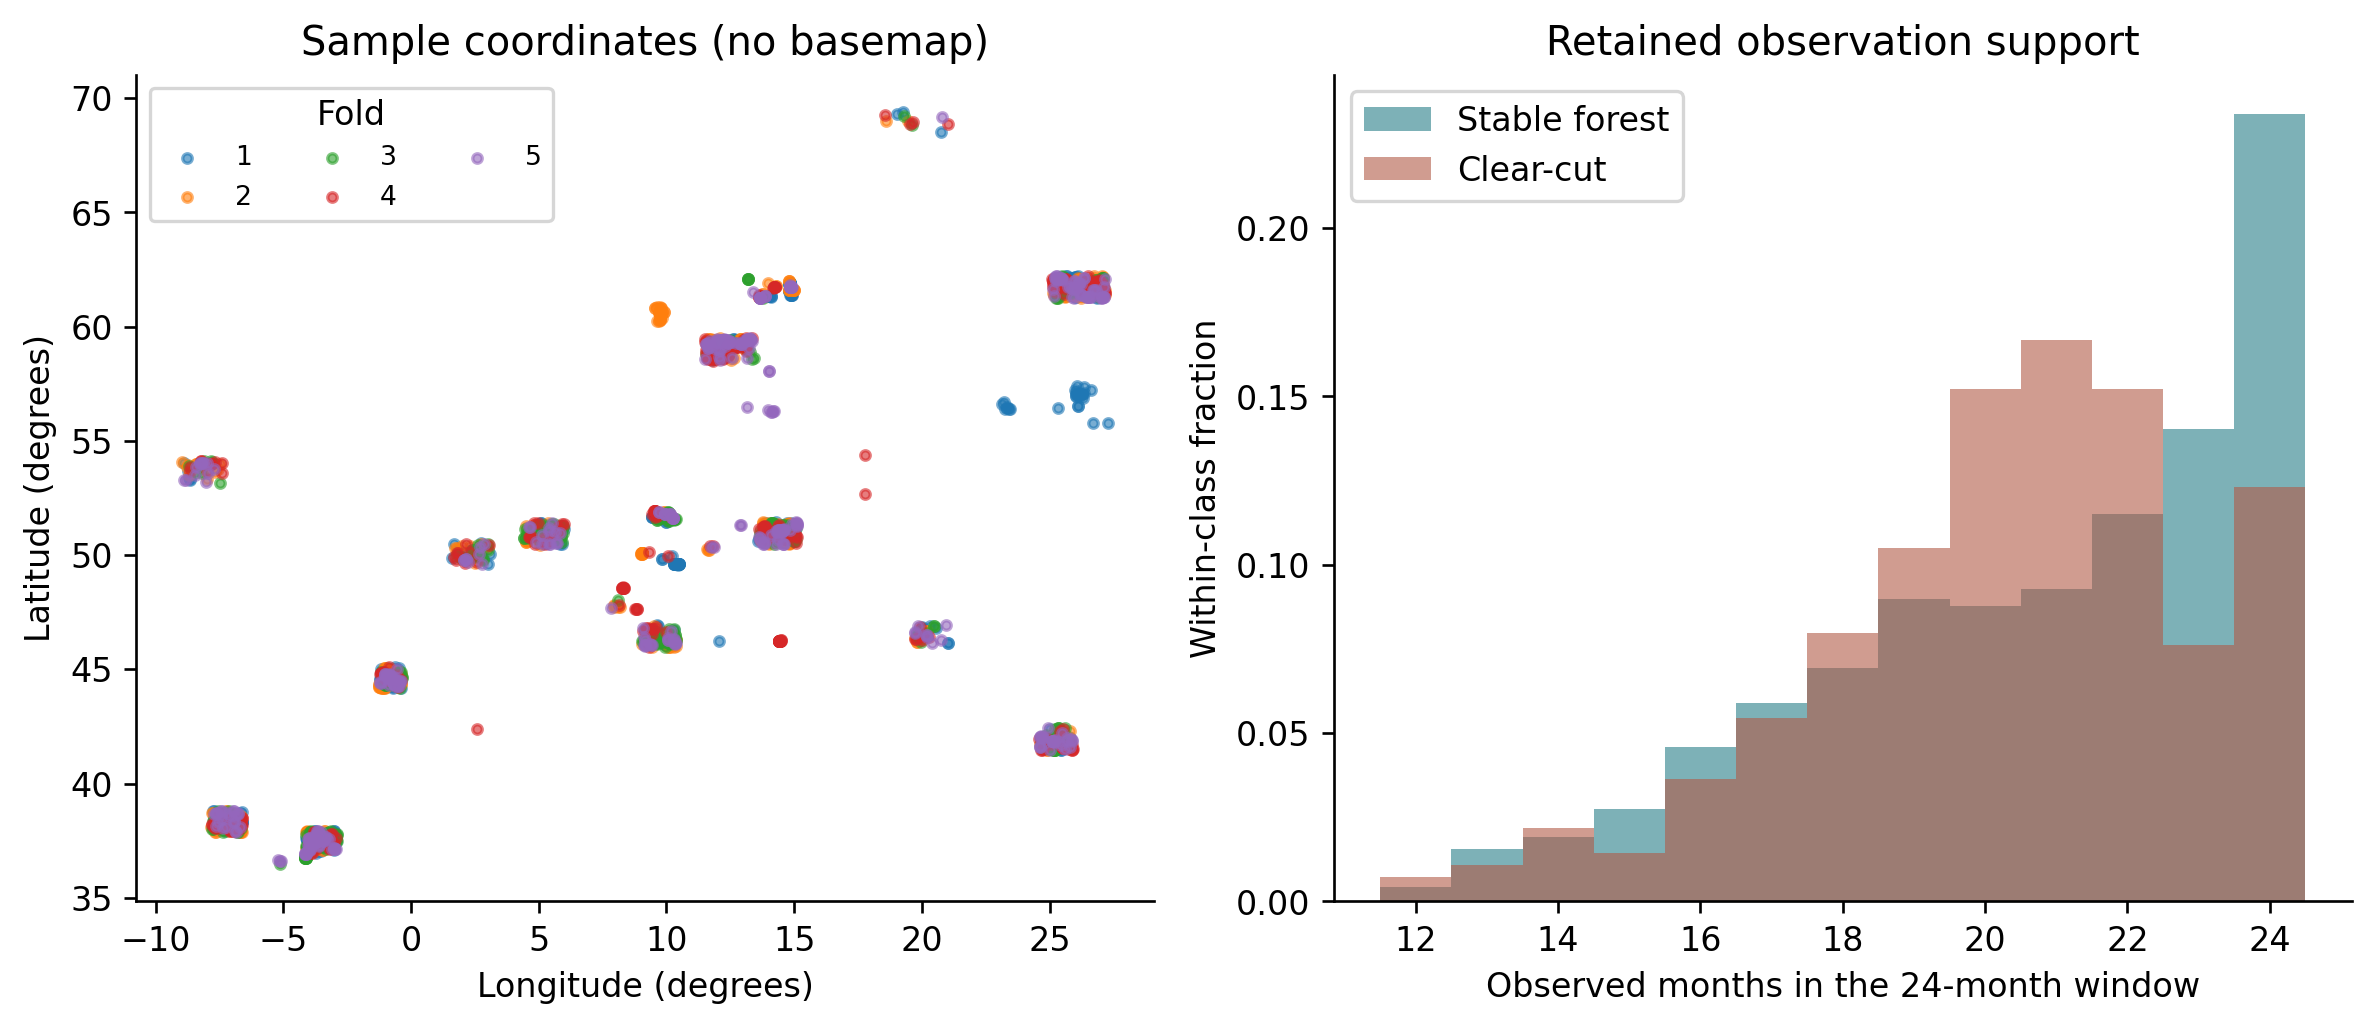

In [17]:
for name, cap in [('01_primary','Figure 2 — Primary comparisons at 20% and 100% labels'),('02_controls','Figure 3 — Controls and paired bootstrap intervals'),('03_data','Figure 1 — Locations and observed-month support')]:
    display(Markdown(f'**{cap}**')); display(Image(filename=str(ROOT/f'paper/figures/{name}.png'), width=900))

In [18]:
# Karışıklık matrisleri (%20 etiket, seed ortalaması değil: üç seed'in toplamı)
rows = []
for m in ['rf_leaf4','cnn64','transformer48','ssl_transformer48','step_matched']:
    cm = sum(confusion_matrix(y, p>=.5, labels=[0,1]) for p in pooled[(m,.2)])
    rows.append(dict(method=NAMES[m], TN=cm[0,0], FP=cm[0,1], FN=cm[1,0], TP=cm[1,1], note='3 seed toplamı (3 × 2213 karar)'))
display(pd.DataFrame(rows))
# Kullanılmamış konum taraması (dış doğrulama için yeterli mi?)
probe = json.loads((ROOT / 'experiments/paper_v4/unused_probe_audit.json').read_text())
print(json.dumps({k: probe[k] for k in list(probe)[:8]}, indent=1, ensure_ascii=False)[:1500])

,method,TN,FP,FN,TP,note
0,Random forest,5586,225,224,604,3 seed toplamı (3 × 2213 karar)
1,Temporal CNN,5598,213,167,661,3 seed toplamı (3 × 2213 karar)
2,Transformer (40 ep.),5437,374,166,662,3 seed toplamı (3 × 2213 karar)
3,Block+band SSL,5584,227,165,663,3 seed toplamı (3 × 2213 karar)
4,Step-matched Transformer,5693,118,168,660,3 seed toplamı (3 × 2213 karar)


{
 "status": "support_audit_only",
 "candidates": 111,
 "class_counts": [
  110,
  1
 ],
 "rejections": {
  "previously_used_point": 2213,
  "not_high_confidence": 598,
  "within_five_km_of_used_point": 476,
  "no_eligible_2017_or_2024_window": 259,
  "shared_source_event": 123,
  "insufficient_monthly_support": 42
 },
 "minimum_distance_km": 5.075658247086252,
 "windows": [
  {
   "id": "probe-40-2017",
   "sample_id": 40,
   "target_year": 2017,
   "lon": -5.193930205161754,
   "lat": 36.49428144254875,
   "label": 0,
   "dataset": 1,
   "distance_km": 7.004722077122834
  },
  {
   "id": "probe-257-2017",
   "sample_id": 257,
   "target_year": 2017,
   "lon": 14.408560102018175,
   "lat": 61.80033428026495,
   "label": 0,
   "dataset": 1,
   "distance_km": 7.063479317858796
  },
  {
   "id": "probe-262-2017",
   "sample_id": 262,
   "target_year": 2017,
   "lon": 14.46582062466537,
   "lat": 61.78862298323157,
   "label": 0,
   "dataset": 1,
   "distance_km": 9.76019573940774
  },
  

## 7. Uzantılar

### 7.1 paper_v5 — gruplama yarıçapı duyarlılığı (tek seed)
Aynı kohort 5 / 10 / 20 km ile yeniden gruplanıp beş yöntem seed 7, %20 etiketle yeniden eğitildi (75 koşu, bütün checkpoint'ler saklı). 5 km koşuları paper_v4'ün seed-7 olasılıklarını 2e-16 hassasiyetle yeniden üretir.

**Table 6 — Grouping-radius sensitivity, 20% labels, seed 7 (pooled OOF macro-F1)**

method,Block+band SSL,Random forest,Step-matched Transformer,Temporal CNN,Transformer (40 ep.)
radius_km,,,,,
5,0.8726,0.8411,0.9017,0.8812,0.8576
10,0.8515,0.8434,0.8429,0.8784,0.8490
20,0.8437,0.8190,0.8216,0.7997,0.7772


AP,Block+band SSL,Random forest,Step-matched Transformer,Temporal CNN,Transformer (40 ep.)
radius_km,,,,,
5,0.8707,0.7924,0.8503,0.8560,0.8518
10,0.8443,0.7734,0.8172,0.8675,0.8244
20,0.8426,0.7425,0.7825,0.7997,0.7829


,radius_km,groups,positive_groups,largest_component
0,5,874,141,45
1,10,205,41,304
2,20,54,20,306


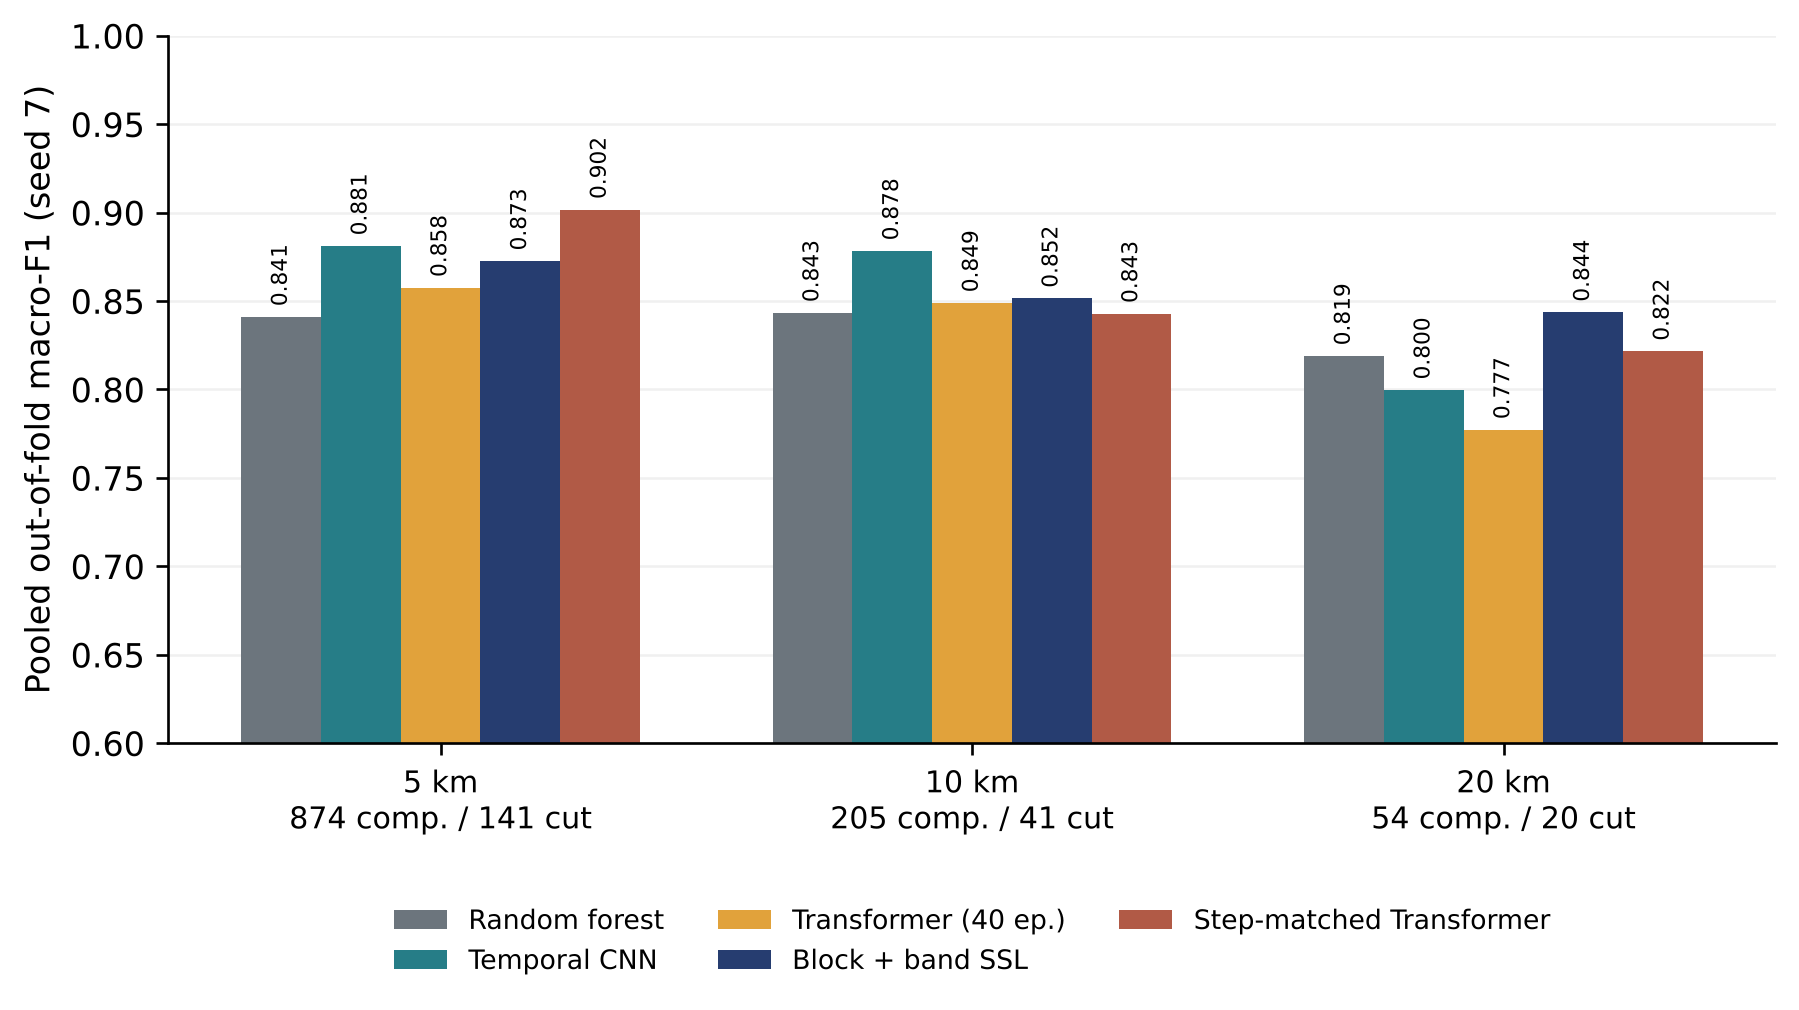

In [19]:
v5 = pd.read_csv(ROOT / 'experiments/paper_v5_exploratory/results.csv')
v5['method'] = v5['method'].map(NAMES)
display(Markdown('**Table 6 — Grouping-radius sensitivity, 20% labels, seed 7 (pooled OOF macro-F1)**'))
display(v5.pivot(index='radius_km', columns='method', values='macro_f1').round(4))
display(v5.pivot(index='radius_km', columns='method', values='average_precision').round(4).rename_axis(columns='AP'))
sup = json.loads((ROOT / 'experiments/paper_v5_exploratory/support_audit.json').read_text())
display(pd.DataFrame([{k: r[k] for k in ['radius_km','groups','positive_groups','largest_component']} for r in sup['radii']]))
display(Image(filename=str(ROOT/'paper/figures/05_radius.png'), width=850))

### 7.2 paper_v6 — etiket bütçesi eğrisi
%5, %10, %50 bütçeleri paper_v4'ün aynı katları, seed'leri ve tarifleriyle (225 koşu). %20 ve %100 satırları paper_v4'ten gelir.

**Table 5 — Label-budget curve (macro-F1 mean ± seed SD)**

method,Block+band SSL,Random forest,Step-matched Transformer,Temporal CNN,Transformer (40 ep.)
5%,0.6955,0.8192,0.8080,0.7946,0.6338
10%,0.7979,0.8362,0.8586,0.8480,0.7670
20%,0.8690,0.8452,0.8987,0.8721,0.8322
50%,0.9049,0.8510,0.9200,0.9100,0.9007
100%,0.9287,0.8669,NaN,0.9299,0.9285


seed SD,Block+band SSL,Random forest,Step-matched Transformer,Temporal CNN,Transformer (40 ep.)
5%,0.0175,0.0126,0.0182,0.0161,0.0699
10%,0.0403,0.0117,0.0030,0.0147,0.0805
20%,0.0043,0.0058,0.0112,0.0081,0.0236
50%,0.0187,0.0035,0.0081,0.0099,0.0071
100%,0.0049,0.0028,NaN,0.0071,0.0057


**SSL minus comparator, per budget (paired component bootstrap)**

,budget,comparator,mean_difference,ci,role
0,0.05,Transformer (40 ep.),0.0618,"[0.0387, 0.0843]",primary
1,0.05,Step-matched Transformer,-0.1124,"[-0.1334, -0.0919]",exploratory
2,0.05,Temporal CNN,-0.0991,"[-0.1208, -0.0783]",exploratory
3,0.05,Random forest,-0.1236,"[-0.1490, -0.0994]",exploratory
4,0.10,Transformer (40 ep.),0.0309,"[0.0161, 0.0459]",primary
5,0.10,Step-matched Transformer,-0.0606,"[-0.0796, -0.0424]",exploratory
6,0.10,Temporal CNN,-0.0501,"[-0.0668, -0.0333]",exploratory
7,0.10,Random forest,-0.0382,"[-0.0637, -0.0140]",exploratory
8,0.50,Transformer (40 ep.),0.0042,"[-0.0087, 0.0179]",primary
9,0.50,Step-matched Transformer,-0.0150,"[-0.0288, -0.0020]",exploratory


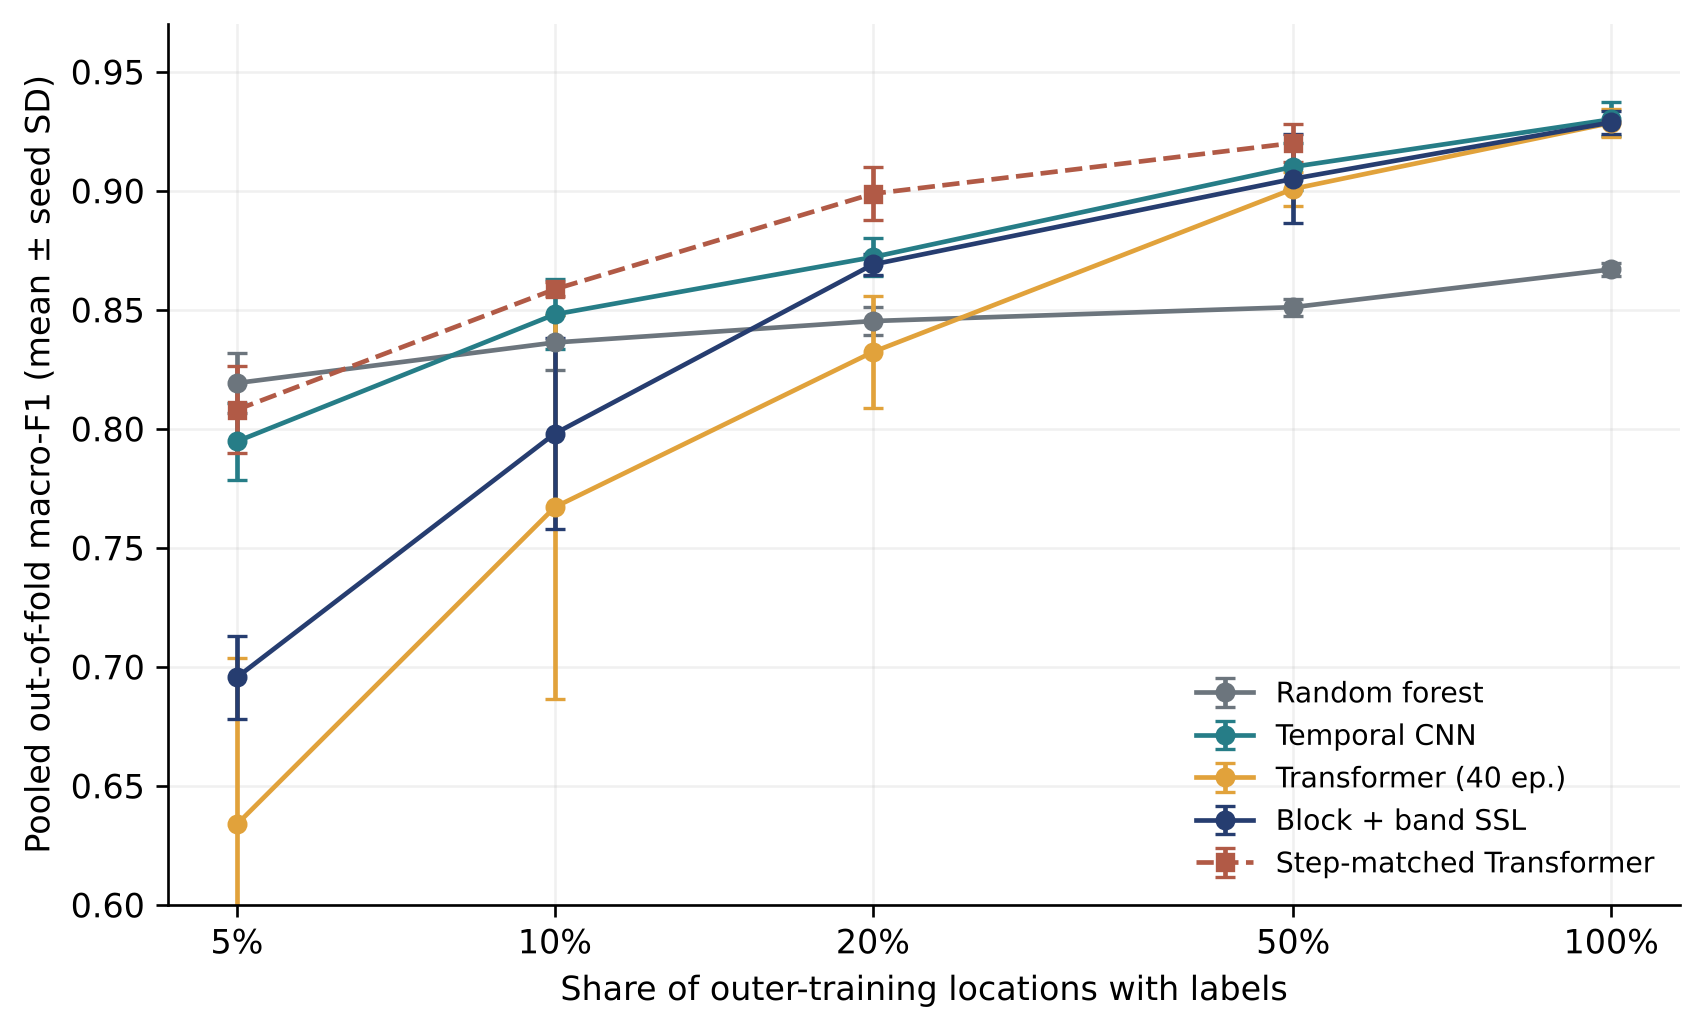

Eğitim ortamı: {'platform': 'Linux-6.18.44-fc-v139-x86_64-with-glibc2.39', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'workers': 2, 'elapsed_wall_seconds': 3254.8062086560003}


In [20]:
v6 = json.loads((ROOT / 'experiments/paper_v6_label_curve/analysis.json').read_text())
curve = pd.DataFrame(v6['combined_curve']); curve['method'] = curve['method'].map(NAMES)
display(Markdown('**Table 5 — Label-budget curve (macro-F1 mean ± seed SD)**'))
piv = curve.pivot(index='budget', columns='method', values='macro_f1_mean').round(4); piv.index = [f'{int(b*100)}%' for b in piv.index]; display(piv)
pivsd = curve.pivot(index='budget', columns='method', values='macro_f1_std').round(4); pivsd.index = piv.index; display(pivsd.rename_axis(columns='seed SD'))
pc = pd.DataFrame(v6['paired_comparisons']); pc['comparator'] = pc['comparator'].map(NAMES)
pc['ci'] = pc['paired_group_bootstrap_95_interval'].apply(lambda v: f'[{v[0]:.4f}, {v[1]:.4f}]')
display(Markdown('**SSL minus comparator, per budget (paired component bootstrap)**')); display(pc[['budget','comparator','mean_difference','ci','role']])
display(Image(filename=str(ROOT/'paper/figures/04_label_curve.png'), width=850))
print('Eğitim ortamı:', {k: v6_exec[k] for k in ['platform','python','torch','workers','elapsed_wall_seconds']} if (v6_exec:=json.loads((ROOT/'experiments/paper_v6_label_curve/execution.json').read_text())) else '')

## 8. Keşif: Presto frozen linear probe
Hazır Presto encoder dondurulup embedding üstünde lojistik regresyon (90 fit). Fine-tune yok; Presto'nun beklediği Sentinel-1, iklim ve yükseklik girdileri yok. Bu yüzden **karşılaştırma değil, sınırlı bir not**.

In [21]:
pr = json.loads((ROOT / 'experiments/presto_v1_exploratory/analysis.json').read_text())
display(pd.DataFrame([dict(method=s['method'], budget=s['budget'], macro_f1=s['macro_f1_mean'], sd=s['macro_f1_std'], AP=s['average_precision_mean']) for s in pr['summary']]))
print('\n'.join(json.loads((ROOT / 'experiments/presto_v1_exploratory/protocol.json').read_text())['limitations']))

,method,budget,macro_f1,sd,AP
0,presto_pretrained_geo,0.2,0.6860,2.3674e-02,0.5005
1,presto_pretrained_constant,0.2,0.7082,7.5215e-03,0.5555
2,presto_random_constant,0.2,0.5717,1.4030e-02,0.2646
3,presto_pretrained_geo,1.0,0.7496,1.3597e-16,0.7077
4,presto_pretrained_constant,1.0,0.7799,0.0000e+00,0.7611
5,presto_random_constant,1.0,0.6436,0.0000e+00,0.4417


Same adaptively examined DISFOR cohort, not external validation
Pretraining data may overlap geographically/temporally; not independently audited
Source DN harmonization/offset compatibility is not independently established
Frozen linear probing only; does not evaluate fully fine-tuned Presto
Pretrained model has external data/compute; not a compute-matched SSL control
Random encoder uses one initialization; label seeds do not capture initialization uncertainty


## 9. Ürün modeli advanced_v3 ve gerçek çıkarım

Makaledeki deneyden **ayrı** bir mühendislik sürümü: 1.266 eğitim / 461 kalibrasyon / 486 test ayrımıyla eğitilmiş 5 CNN + 5 SSL Transformer ensemble'ı; olasılıklar ortalanıp kalibrasyon kümesinde Platt ölçeklenmiş, eşik oradan seçilmiş. Ağırlıklar `models/advanced_v3/*.pt`, hash'ler `bundle.json`. Aşağıda 486 örnekte gerçek çıkarım yapılır ve kayıtlı sonuçla karşılaştırılır. Ürün arayüzü: `URUNU_AC.command` → `scripts/serve_product.py` → `reports/product.html`.

In [22]:
bundle = json.loads((ROOT / 'models/advanced_v3/bundle.json').read_text())
print('Üyeler:', [m['path'] for m in bundle['members']]); print('Kalibrasyon:', bundle['calibration'], '| eşik:', bundle['threshold'])
card = json.loads((ROOT / 'models/advanced_v3/model_card.json').read_text()); print(json.dumps(card, indent=1, ensure_ascii=False)[:1800])
inp = dict(np.load(ROOT / 'output/advanced_prediction/input.npz', allow_pickle=False))
t0 = time.time(); res = adv.ensemble_predict(ROOT / 'models/advanced_v3/bundle.json', inp); print(f'486 örnekte 10 üyeli çıkarım: {time.time()-t0:.1f} s')
saved = json.loads((ROOT / 'output/advanced_prediction/predictions.json').read_text())
print('Kayıtlı tahminle en büyük olasılık farkı:', float(np.max(np.abs(np.array(res['probabilities'])[:,1] - np.array(saved['probabilities'])[:,1]))))
ev = json.loads((ROOT / 'experiments/advanced_v3/evaluation.json').read_text())
labels486 = manifest.set_index('id').loc[res['ids'], 'label'].values
cm = confusion_matrix(labels486, np.array(res['predictions']), labels=[0,1])
display(pd.DataFrame(cm, index=['gerçek orman','gerçek kesim'], columns=['tahmin orman','tahmin kesim']))
print('macro-F1 (486 örnek):', round(f1_score(labels486, res['predictions'], average='macro'), 4), '| model_card kayıtlı:', round(card['metrics']['macro_f1'], 4))

Üyeler: ['ssl_transformer48_7.pt', 'ssl_transformer48_17.pt', 'ssl_transformer48_27.pt', 'ssl_transformer48_37.pt', 'ssl_transformer48_47.pt', 'cnn64_7.pt', 'cnn64_17.pt', 'cnn64_27.pt', 'cnn64_37.pt', 'cnn64_47.pt']
Kalibrasyon: {'slope': 1.4209698458105833, 'intercept': -2.1766242893584375} | eşik: 0.5
{
 "name": "Orman-SSL advanced_v3",
 "status": "trained and verified local research model",
 "task": "Retrospective clear-cut versus undisturbed forest; two full calendar years; 10 Sentinel-2 DN bands",
 "architecture": [
  {
   "config": {
    "name": "ssl_transformer48",
    "kind": "transformer",
    "width": 48,
    "dropout": 0.15,
    "lr": 0.0005,
    "ssl": true
   },
   "members": 5,
   "epochs": 36
  },
  {
   "config": {
    "name": "cnn64",
    "kind": "cnn",
    "width": 64,
    "dropout": 0.2,
    "lr": 0.001
   },
   "members": 5,
   "epochs": 21
  }
 ],
 "selection": "Four spatial-group folds inside training only; fixed top-two rule",
 "training_points": 1266,
 "calibra

486 örnekte 10 üyeli çıkarım: 0.3 s
Kayıtlı tahminle en büyük olasılık farkı: 2.384185791015625e-07


,tahmin orman,tahmin kesim
gerçek orman,448,0
gerçek kesim,10,28


macro-F1 (486 örnek): 0.9187 | model_card kayıtlı: 0.9187


In [23]:
show_source(adv.ensemble_predict)
print((ROOT / 'scripts/run_advanced.py').read_text()[:3000])

**Kaynak: `ensemble_predict`**

def ensemble_predict(bundle_path,data):
    validate_input(data);bundle_path=Path(bundle_path);bundle=json.loads(bundle_path.read_text());preds=[]
    for member in bundle['members']:
        path=bundle_path.parent/member['path']
        if digest(path)!=member['sha256']:raise ValueError('Model member hash mismatch: '+member['path'])
        preds.append(state_probability(load_state(path),data))
    values=np.stack(preds);raw=values.mean(0);cal=bundle['calibration']
    p=sigmoid(cal['slope']*logit(raw)+cal['intercept']);m=data['observed'].any(-1)
    eligible=(m[:,:12].sum(1)>=6)&(m[:,12:].sum(1)>=6)
    return dict(ids=data['ids'].tolist(),predictions=(p>=bundle['threshold']).astype(int).tolist(),
                probabilities=np.stack([1-p,p],axis=1).tolist(),raw_probabilities=raw.tolist(),member_std=values.std(0).tolist(),
                quality_eligible=eligible.tolist(),classes=bundle['classes'],threshold=bundle['threshold'],
                note='Calibrated on development geog

## 10. Doğrulama ve tekrar üretim

`verify_paper.py` 180 kaydı okuyup OOF vektörlerini yeniden kurar, metrikleri yeniden hesaplar, hash'leri ve "validation ile seçim yapılmadı" kuralını denetler. Testler `tests/` altındadır.

In [24]:
import subprocess
r = subprocess.run([sys.executable, str(ROOT/'scripts/verify_paper.py')], cwd=ROOT, capture_output=True, text=True); print(r.stdout[-1500:], r.stderr[-500:])
r = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests'], cwd=ROOT, capture_output=True, text=True); print(r.stderr[-400:])

{
  "status": "passed",
  "fits": 180,
  "oof_predictions": 79668,
  "checks": [
    "frozen code/data/protocol SHA-256",
    "exact declared jobs",
    "fold identities",
    "paired labeled subsets",
    "training/test disjointness",
    "prediction ranges and label alignment",
    "fixed epochs and no validation selection",
    "pretraining histories",
    "complete OOF reconstruction",
    "recomputed macro-F1 and average precision"
  ]
}
 


......................................................................................
----------------------------------------------------------------------
Ran 86 tests in 5.064s

OK



### Tam tekrar üretim komutları (proje kökünde, `.venv` ile)

```bash
.venv/bin/python scripts/prepare_disfor.py                  # ham DISFOR → real_series.npz
.venv/bin/python scripts/train_paper.py --workers 3         # paper_v4: 180 fit (önbellek varsa atlar)
.venv/bin/python scripts/analyze_paper.py                   # tablolar + bootstrap → analysis.json
.venv/bin/python scripts/plot_paper.py                      # Figure 1–3
.venv/bin/python scripts/scientific_v5.py prepare|train|analyze ; scripts/verify_spatial_v5.py ; scripts/report_spatial_v5.py
.venv/bin/python scripts/label_curve_v6.py prepare|train|analyze ; scripts/plot_extensions.py
.venv/bin/python scripts/compose_paper.py && scripts/build_paper_docx.py   # makale
.venv/bin/python scripts/build_final_report.py              # Türkçe rapor
.venv/bin/python scripts/verify_paper.py ; scripts/verify_advanced.py ; scripts/verify_final_delivery.py
.venv/bin/python -m unittest discover -s tests -v
```

### Dosya haritası

| Ne | Nerede |
|---|---|
| Ham veri, lisans | `data/disfor/` |
| Model girdisi | `data/processed/real_series.npz` |
| Model kodu | `src/orman_ssl/advanced.py`, `experiment.py`, `inputs.py` |
| Ana deney kayıtları | `experiments/paper_v4/{protocol,folds,jobs,signature,analysis,verification}.json`, `runs/` |
| Uzantılar | `experiments/paper_v5_exploratory/`, `experiments/paper_v6_label_curve/` |
| Ürün modeli | `models/advanced_v3/` |
| Makale | `paper/manuscript.md`, `output/pdf/Orman_SSL_Manuscript.pdf` |
| Türkçe rapor | `output/final/` |
| Ürün arayüzü | `URUNU_AC.command`, `scripts/serve_product.py`, `reports/product.html` |